# Unit 3 Correlation and Regression
This notebook works through the four exercises supplied by the University of Essex. For each, I ran the supplied example first, then changed one thing at a time to see how the data shape the result. The original notebooks are unchanged. Exercise 3 needs a `cars.csv` file that was not supplied, so it uses the public W3Schools teaching data instead. These are small teaching examples, not tested forecasting models.

In [1]:
from datetime import datetime, timezone
print("Run by Anne Dayer (student 39359) on my computer on",
      datetime.now(timezone.utc).strftime("%d %B %Y at %H:%M UTC"))

Run by Anne Dayer (student 39359) on my computer on 28 October 2026 at 16:49 UTC


In [2]:
import sys, platform
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
print('Python:', platform.python_version())
print({m.__name__: m.__version__ for m in [np, pd, scipy, sklearn, matplotlib]})
plt.rcParams.update({'figure.figsize': (7,4), 'axes.grid': True})
pd.set_option('display.max_columns', 12)

Python: 3.14.9
{'numpy': '2.5.0', 'pandas': '3.1.0', 'scipy': '1.18.1', 'sklearn': '1.9.1', 'matplotlib': '3.11.2'}


## Exercise 1 Covariance and Pearson correlation
**Starting point:** seed 1, 1,000 points, `x = 20 * randn + 100` and `y = x + 10 * randn + 50`.

Each time I changed the noise, the direction, an added constant or the units, I kept the same x values and the same random noise, so that only one thing changed. Covariance and standard deviation both divide by n − 1 (`ddof=1`) to keep them consistent; the supplied notebook divided the standard deviation by n.

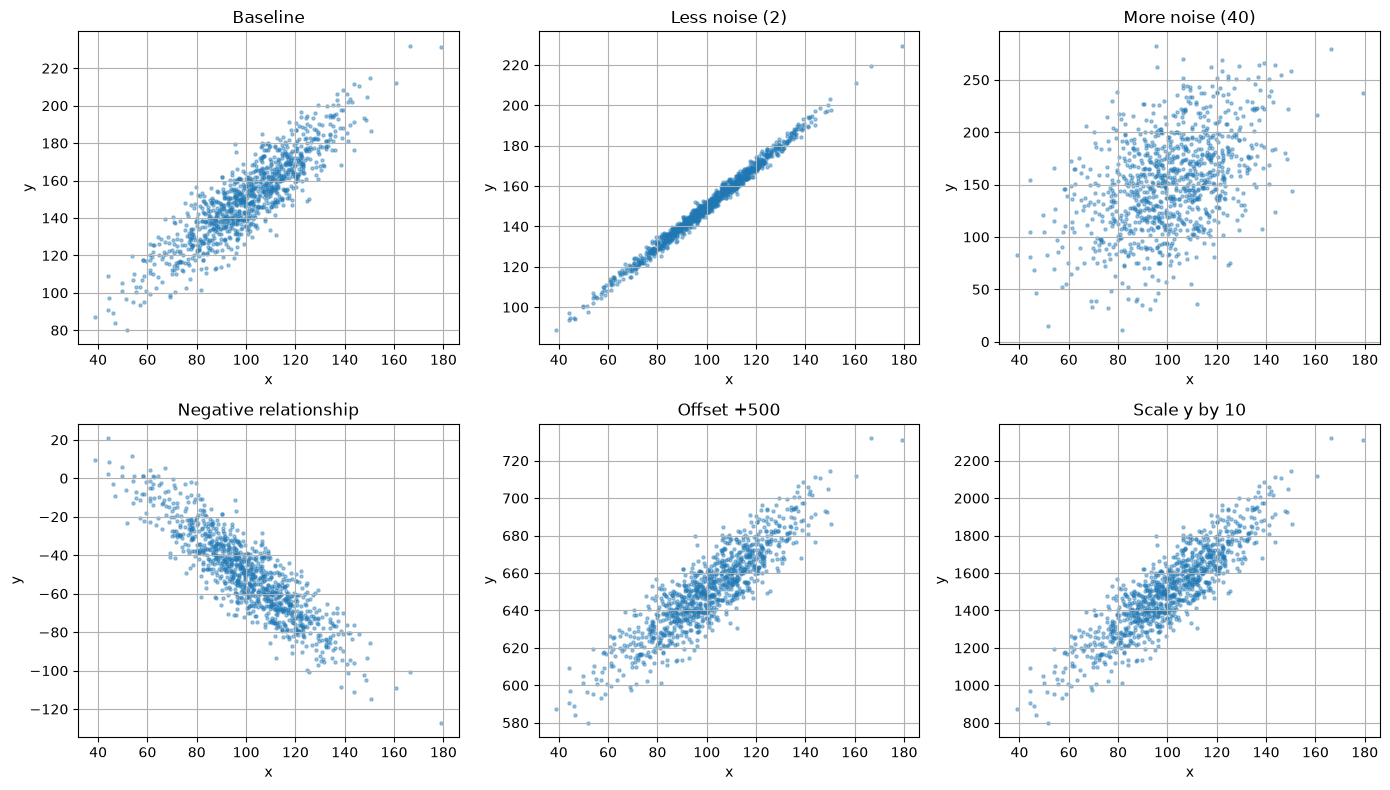

,Experiment,n,Covariance,Pearson r,Mean y,Sample SD y
0,Baseline,1000,389.7546,0.8876,151.0495,22.3692
1,Less noise (2),1000,386.2173,0.9946,150.8309,19.7826
2,More noise (40),1000,403.0193,0.4459,151.8693,46.0431
3,Negative relationship,1000,-380.9114,-0.8832,-50.5030,21.9703
4,Offset +500,1000,389.7546,0.8876,651.0495,22.3692
5,Scale y by 10,1000,3897.5456,0.8876,1510.4950,223.6918


Baseline x mean=100.776; sample SD=19.630
PASS: Exercise 1 baseline and controlled-change checks.


In [3]:
rng = np.random.RandomState(1)
x_corr = 20*rng.randn(1000)+100
noise = rng.randn(1000)
y_base = x_corr+10*noise+50
cases = {'Baseline': y_base, 'Less noise (2)': x_corr+2*noise+50,
         'More noise (40)': x_corr+40*noise+50,
         'Negative relationship': -x_corr+10*noise+50,
         'Offset +500': y_base+500, 'Scale y by 10': y_base*10}
rows=[]
fig, axes=plt.subplots(2,3,figsize=(14,8))
for ax,(name,y) in zip(axes.flat,cases.items()):
    r,p=stats.pearsonr(x_corr,y)
    rows.append({'Experiment':name,'n':len(y),'Covariance':np.cov(x_corr,y)[0,1], 'Pearson r':r,
                 'Mean y':y.mean(), 'Sample SD y':y.std(ddof=1)})
    ax.scatter(x_corr,y,s=5,alpha=.4); ax.set(title=name,xlabel='x',ylabel='y')
plt.tight_layout(); plt.show()
corr_results=pd.DataFrame(rows)
display(corr_results.round(4))
print(f'Baseline x mean={x_corr.mean():.3f}; sample SD={x_corr.std(ddof=1):.3f}')
assert np.isclose(corr_results.iloc[0]['Pearson r'], corr_results.iloc[4]['Pearson r'])
assert np.isclose(corr_results.iloc[0]['Pearson r'], corr_results.iloc[5]['Pearson r'])
# Check that the results are as expected
assert np.isclose(corr_results.iloc[0]['Pearson r'], 0.887611908579531, atol=1e-8)
assert np.isclose(corr_results.iloc[0]['Covariance'], 389.754561997836, atol=1e-3)
print('PASS: Exercise 1 baseline and controlled-change checks.')

**What I found.** More noise weakened the straight-line relationship, and reversing the direction made r negative. Adding a constant to y changed neither the covariance nor r. Multiplying y by a positive number scaled the covariance but left r the same. Covariance therefore depends on the units, while r does not. Neither shows cause, and r can miss a curved relationship.

## Exercise 2 Simple linear regression
The supplied first cell imports `stats` but then calls `stat`, which stops with an error, so I corrected both calls. I kept the original points. The starting model predicts y at x = 10; the other runs add a constant, add noise, or move one point to create an outlier. I drew the line over sorted x values, because the points are not in order and the line would otherwise double back on itself.

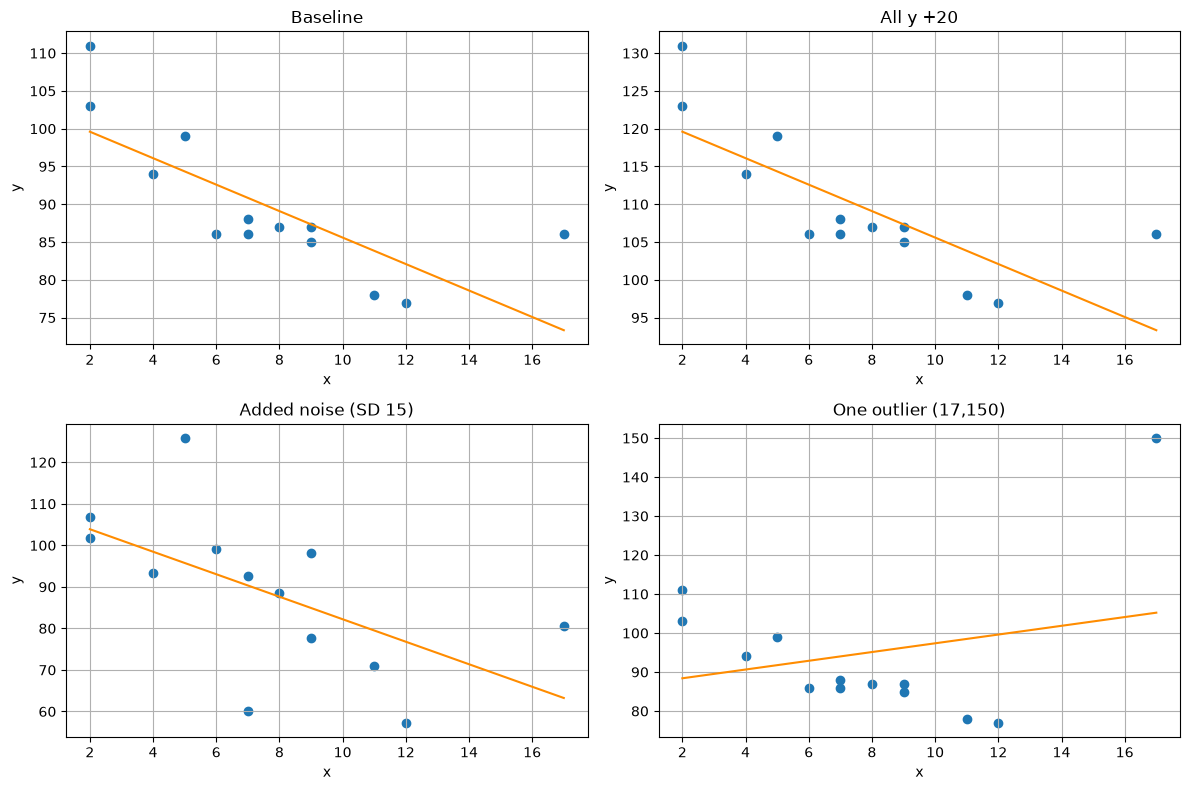

,Experiment,Slope,Intercept,Pearson r,Training R2,Prediction x=10
0,Baseline,-1.7513,103.1060,-0.7586,0.5755,85.5931
1,All y +20,-1.7513,123.1060,-0.7586,0.5755,105.5931
2,Added noise (SD 15),-2.7094,109.3029,-0.5885,0.3464,82.2091
3,"One outlier (17,150)",1.1214,86.1523,0.2441,0.0596,97.3664


PASS: Exercise 2 baseline, offset and outlier checks.


In [4]:
x_lin=np.array([5,7,8,7,2,17,2,9,4,11,12,9,6],dtype=float)
y_lin=np.array([99,86,87,88,111,86,103,87,94,78,77,85,86],dtype=float)
outlier=y_lin.copy(); outlier[np.argmax(x_lin)]=150
lin_cases={'Baseline':y_lin,'All y +20':y_lin+20,
           'Added noise (SD 15)':y_lin+np.random.RandomState(3).normal(0,15,len(y_lin)),
           'One outlier (17,150)':outlier}
rows=[]; fig,axes=plt.subplots(2,2,figsize=(12,8)); grid=np.linspace(x_lin.min(),x_lin.max(),100)
for ax,(name,y) in zip(axes.flat,lin_cases.items()):
    fit=stats.linregress(x_lin,y)
    rows.append({'Experiment':name,'Slope':fit.slope,'Intercept':fit.intercept,'Pearson r':fit.rvalue,
                 'Training R2':fit.rvalue**2,'Prediction x=10':fit.intercept+10*fit.slope})
    ax.scatter(x_lin,y); ax.plot(grid,fit.intercept+fit.slope*grid,color='darkorange')
    ax.set(title=name,xlabel='x',ylabel='y')
plt.tight_layout(); plt.show()
linear_results=pd.DataFrame(rows); display(linear_results.round(4))
assert np.isclose(linear_results.iloc[0]['Prediction x=10'],85.593083,atol=1e-5)
assert np.isclose(linear_results.iloc[0]['Slope'],linear_results.iloc[1]['Slope'])
# Check that the results are as expected
assert np.isclose(linear_results.iloc[1]['Prediction x=10']-linear_results.iloc[0]['Prediction x=10'], 20)
assert linear_results.iloc[0]['Slope'] < 0 < linear_results.iloc[3]['Slope']
print('PASS: Exercise 2 baseline, offset and outlier checks.')

**What I found.** The starting slope is negative. Adding 20 to every y raised the intercept and the prediction by 20 but left the slope and r unchanged. Noise changed the line. The outlier showed how one point, especially at the edge of the data, can change the slope sharply. R² here measures the fit on the same points the line was fitted to, so it says nothing about future accuracy. The prediction at x = 10 lies inside the data.

## Exercise 3 Multiple linear regression
The supplied notebook expects a `cars.csv` file that was not provided. I used the number columns of the public W3Schools example instead (https://www.w3schools.com/python/trypandas.asp?filename=demo_ml_coef), because its coefficients and prediction match the supplied notes. It is a replacement; I have not seen the missing Essex file.

Weight is in kg, engine volume in cm³ and CO₂ in g/km. To see the effect of each input, I changed one input at a time and kept the fitted model the same. In a second test I changed one training value and fitted the model again, which is a different operation.

In [5]:
url='https://www.w3schools.com/python/data.csv'
from io import StringIO
# Number columns copied from the W3Schools example linked above.
# Typed in because the website refused the download (error 403); it also lets the notebook run offline.
df=pd.read_csv(StringIO('Volume,Weight,CO2\n1000,790,99\n1200,1160,95\n1000,929,95\n900,865,90\n1500,1140,105\n1000,929,105\n1400,1109,90\n1500,1365,92\n1500,1112,98\n1600,1150,99\n1100,980,99\n1300,990,101\n1000,1112,99\n1600,1252,94\n1600,1326,97\n1600,1330,97\n1600,1365,99\n2200,1280,104\n1600,1119,104\n2000,1328,105\n1600,1584,94\n2000,1428,99\n2100,1365,99\n1600,1415,99\n2000,1415,99\n1500,1465,102\n2000,1490,104\n2000,1725,114\n1600,1523,109\n2000,1705,114\n2100,1605,115\n2000,1746,117\n1600,1235,104\n1600,1390,108\n1600,1405,109\n2500,1395,120\n'))
assert len(df)==36 and {'Weight','Volume','CO2'}.issubset(df.columns)
assert not df[['Weight','Volume','CO2']].isna().any().any()
df.to_csv('cars.csv',index=False)
print('Dataset source:',url,'; rows:',len(df), '; numeric teaching data embedded for reproducibility')
display(df.head())
X=df[['Weight','Volume']]; y=df['CO2']
multiple=LinearRegression().fit(X,y)
print('Intercept:', multiple.intercept_)
display(pd.DataFrame({'Feature':X.columns,'Coefficient':multiple.coef_}))
inputs=pd.DataFrame([[2300,1300],[3300,1300],[2300,2300]],columns=X.columns)
inputs['Predicted CO2 g/km']=multiple.predict(inputs)
inputs['Change from baseline']=inputs['Predicted CO2 g/km']-inputs['Predicted CO2 g/km'].iloc[0]
inputs['Outside observed feature ranges']=[any(v< X[c].min() or v>X[c].max() for c,v in zip(X.columns,row)) for row in [[2300,1300],[3300,1300],[2300,2300]]]
display(inputs.round(4))
print('Observed ranges:'); display(X.agg(['min','max']))
changed_y=y.copy(); changed_y.iloc[0]+=50
changed_model=LinearRegression().fit(X,changed_y)
display(pd.DataFrame({'Model':['Baseline','First training CO2 +50'],
'Weight coefficient':[multiple.coef_[0],changed_model.coef_[0]],
'Volume coefficient':[multiple.coef_[1],changed_model.coef_[1]],
'Prediction (2300,1300)':[multiple.predict(X.iloc[:1].assign(Weight=2300,Volume=1300))[0],changed_model.predict(X.iloc[:1].assign(Weight=2300,Volume=1300))[0]]}).round(5))
print('Predictor correlation:', X.corr().iloc[0,1])
cv_predictions=cross_val_predict(LinearRegression(),X,y,cv=LeaveOneOut())
print(f'Training R2={multiple.score(X,y):.4f}; leave-one-out prediction R2={r2_score(y,cv_predictions):.4f}')
assert np.isclose(inputs.iloc[0]['Predicted CO2 g/km'],107.2087328,atol=1e-5)
# Check that the results are as expected
assert np.allclose(multiple.coef_, [0.0075509472703, 0.00780525752775], atol=1e-8)
assert np.isclose(inputs.iloc[1]['Predicted CO2 g/km'],114.75968007,atol=1e-5)
assert inputs['Outside observed feature ranges'].all()
print('PASS: Exercise 3 coefficients, predictions and extrapolation checks.')

Dataset source: https://www.w3schools.com/python/data.csv ; rows: 36 ; numeric teaching data embedded for reproducibility


,Volume,Weight,CO2
0,1000,790,99
1,1200,1160,95
2,1000,929,95
3,900,865,90
4,1500,1140,105


Intercept: 79.69471929115939


,Feature,Coefficient
0,Weight,0.007551
1,Volume,0.007805


,Weight,Volume,Predicted CO2 g/km,Change from baseline,Outside observed feature ranges
0,2300,1300,107.2087,0.0000,True
1,3300,1300,114.7597,7.5509,True
2,2300,2300,115.0140,7.8053,True


Observed ranges:


,Weight,Volume
min,790,900
max,1746,2500


,Model,Weight coefficient,Volume coefficient,"Prediction (2300,1300)"
0,Baseline,0.00755,0.00781,107.20873
1,First training CO2 +50,-0.00461,0.00774,96.36610


Predictor correlation: 0.7535372689189783
Training R2=0.3766; leave-one-out prediction R2=0.2161
PASS: Exercise 3 coefficients, predictions and extrapolation checks.


**What I found.** Each coefficient shows how CO₂ changes with one input while the other stays fixed; it does not prove cause. Adding 1,000 kg changes the prediction by 1,000 times the weight coefficient, without adding a car or refitting. 2,300 kg and 3,300 kg are both heavier than the heaviest car in the data (1,746 kg), so all three example predictions go beyond the data. Changing one training value and refitting changed the coefficients. When two inputs rise together, their separate coefficients are less stable, and the size of a coefficient also depends on its units. Leave-one-out predicts each car from a model fitted without it, which suits a small dataset, but 36 teaching cars cannot support an emissions policy.

## Exercise 4 Polynomial regression
I kept the original 18 time and speed points and the supplied cubic model. I compared degrees 1, 2, 3 and 6 on the same points, then changed one speed while keeping degree 3. For each model, I report the fit on the training points and the leave-one-out prediction score. The polynomial terms are built inside each leave-one-out round, so the point being predicted never helps to build them.

R² can be negative. Zero means the model does no better than always predicting the average, so a high training R² does not prove that predictions will be good.

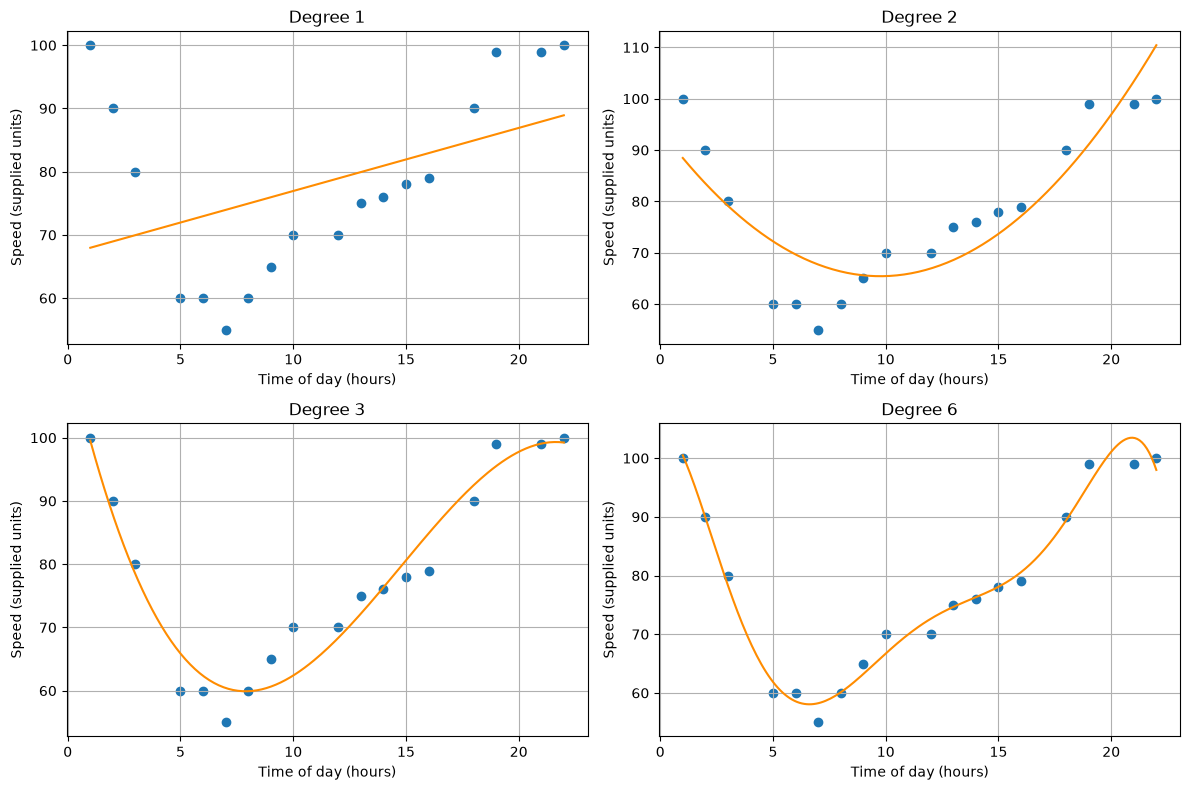

,Degree,Training R2,LOO R2,LOO RMSE,Prediction at 17,Prediction at 30
0,1,0.1823,-0.1304,15.7576,83.9297,96.8968
1,2,0.7598,0.5946,9.4370,81.1757,188.4271
2,3,0.9432,0.9184,4.2348,88.8733,37.9539
3,6,0.9799,0.8148,6.3776,84.2887,-1837.6339


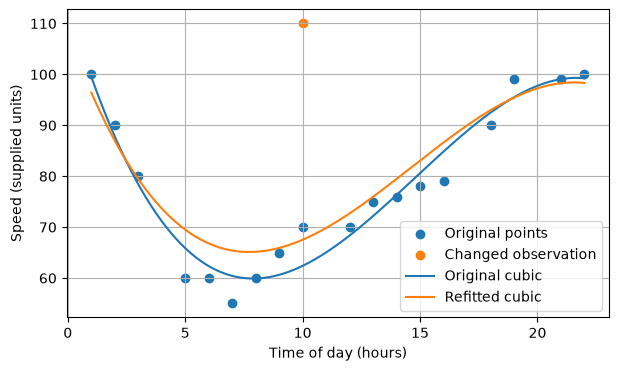

At 17: original cubic=88.8733; changed-point cubic=89.9782
PASS: Exercise 4 cubic baseline and validation checks.


In [6]:
x_poly=np.array([1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22],dtype=float)
y_poly=np.array([100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100],dtype=float)
rows=[]; fig,axes=plt.subplots(2,2,figsize=(12,8)); grid=np.linspace(1,22,200)
for ax,degree in zip(axes.flat,[1,2,3,6]):
    model=np.poly1d(np.polyfit(x_poly,y_poly,degree))
    pipeline=make_pipeline(StandardScaler(),PolynomialFeatures(degree,include_bias=False),LinearRegression())
    cv_pred=cross_val_predict(pipeline,x_poly.reshape(-1,1),y_poly,cv=LeaveOneOut())
    rows.append({'Degree':degree,'Training R2':r2_score(y_poly,model(x_poly)),
                 'LOO R2':r2_score(y_poly,cv_pred),'LOO RMSE':np.sqrt(mean_squared_error(y_poly,cv_pred)),
                 'Prediction at 17':model(17),'Prediction at 30':model(30)})
    ax.scatter(x_poly,y_poly); ax.plot(grid,model(grid),color='darkorange')
    ax.set(title=f'Degree {degree}',xlabel='Time of day (hours)',ylabel='Speed (supplied units)')
plt.tight_layout(); plt.show()
polynomial_results=pd.DataFrame(rows); display(polynomial_results.round(4))
changed_speed=y_poly.copy(); changed_speed[8]+=40
base_cubic=np.poly1d(np.polyfit(x_poly,y_poly,3)); changed_cubic=np.poly1d(np.polyfit(x_poly,changed_speed,3))
plt.scatter(x_poly,y_poly,label='Original points'); plt.scatter([x_poly[8]],[changed_speed[8]],label='Changed observation')
plt.plot(grid,base_cubic(grid),label='Original cubic'); plt.plot(grid,changed_cubic(grid),label='Refitted cubic')
plt.xlabel('Time of day (hours)'); plt.ylabel('Speed (supplied units)'); plt.legend(); plt.show()
print(f'At 17: original cubic={base_cubic(17):.4f}; changed-point cubic={changed_cubic(17):.4f}')
assert np.isclose(r2_score(y_poly,base_cubic(x_poly)),0.9432150416,atol=1e-8)
# Check that the results are as expected
assert np.isclose(base_cubic(17),88.87331269698001,atol=1e-6)
assert (polynomial_results['LOO RMSE'] > 0).all()
assert polynomial_results.loc[polynomial_results['Degree']==3,'LOO RMSE'].iloc[0] < polynomial_results.loc[polynomial_results['Degree']==6,'LOO RMSE'].iloc[0]
print('PASS: Exercise 4 cubic baseline and validation checks.')

**What I found.** The curve lets the model follow the fall and then the rise in speed. Extra polynomial terms can never make the training fit worse, but predictions need not improve, so I compared the leave-one-out RMSE (the typical prediction error) before preferring a higher degree. Changing one point moved the whole cubic curve. The prediction at 17:00 lies inside the data. x = 30 lies outside the data and outside a 24-hour day, so I show it only as a warning about predicting beyond the data, not as a traffic forecast. Time of day repeats every 24 hours, which these curves cannot capture.

## Learning outcome links and responsible use
**Dataset applicability:** these tests show the effect of noise, outliers, units, related inputs and model degree. The amount of data, and the range it covers, limits what I can conclude, especially outside that range.

**Legal, social, ethical and professional issues:** the car table and simulated data are for learning, not for decisions about real people. Before reusing a real dataset, I would check its licence, its origin, the uses allowed and any privacy obligations; being free to download does not permit every use. For decisions that matter, I would check whether the data represent the people affected, how uncertain the results are, and whether errors fall more heavily on some groups. I kept the sources and recorded my corrections, so that results from teaching examples are not presented as real-world evidence.

## Sources
- scikit-learn developers (no date a) *r2_score*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html (Accessed: 22 October 2026).
- scikit-learn developers (no date b) *LeaveOneOut*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.LeaveOneOut.html (Accessed: 22 October 2026).
- SciPy developers (no date a) *scipy.stats.linregress*. Available at: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html (Accessed: 22 October 2026).
- SciPy developers (no date b) *scipy.stats.pearsonr*. Available at: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html (Accessed: 22 October 2026).
- W3Schools (no date a) *Python Machine Learning Multiple Regression: data.csv* [Dataset]. Available at: https://www.w3schools.com/python/python_ml_multiple_regression.asp (Accessed: 22 October 2026).
- W3Schools (no date b) *About Terms of Service*. Available at: https://www.w3schools.com/about/about_copyright.asp (Accessed: 22 October 2026).

Supplied materials: University of Essex Online Unit 3 activity brief and four example notebooks. The code adapts the supplied examples.

In [7]:
print('PASS: ALL FOUR EXERCISES COMPLETED. All numerical checks passed; no export helper is needed to run these exercises.')

PASS: ALL FOUR EXERCISES COMPLETED. All numerical checks passed; no export helper is needed to run these exercises.
